In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/train.csv")
print(df.shape)
df.head()


(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


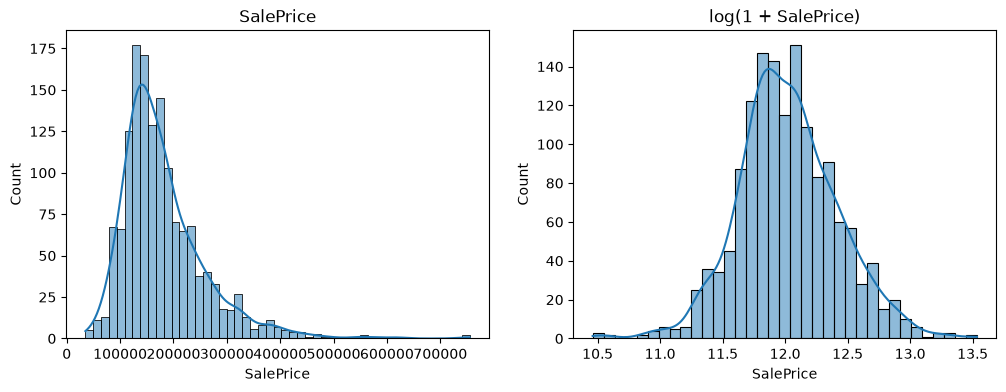

Skew: 1.8828757597682129
Skew after log: 0.12134661989685333


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SalePrice"], kde=True, ax=ax[0])
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=ax[1])
ax[0].set_title("SalePrice")
ax[1].set_title("log(1 + SalePrice)")
plt.show()

print("Skew:", df["SalePrice"].skew())
print("Skew after log:", np.log1p(df["SalePrice"]).skew())

In [3]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print(len(missing), "columns have missing values")
print(missing.head(10))

19 columns have missing values
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
dtype: int64


In [4]:
has_pool = df["PoolArea"] > 0

print("Houses with a pool:", has_pool.sum())
print("PoolQC missing:", df["PoolQC"].isna().sum())
print("Has pool BUT PoolQC missing:", (has_pool & df["PoolQC"].isna()).sum())
print("No pool BUT PoolQC filled:", (~has_pool & df["PoolQC"].notna()).sum())

Houses with a pool: 7
PoolQC missing: 1453
Has pool BUT PoolQC missing: 0
No pool BUT PoolQC filled: 0


In [5]:
has_pool = df["PoolArea"] > 0

print("Houses with a pool:", has_pool.sum())
print("PoolQC missing:", df["PoolQC"].isna().sum())
print("Has pool BUT PoolQC missing:", (has_pool & df["PoolQC"].isna()).sum())
print("No pool BUT PoolQC filled:", (~has_pool & df["PoolQC"].notna()).sum())

Houses with a pool: 7
PoolQC missing: 1453
Has pool BUT PoolQC missing: 0
No pool BUT PoolQC filled: 0


In [6]:
print(df.dtypes.value_counts())
print()
print(df.select_dtypes(include="number").columns.tolist())
print()
print(df.select_dtypes(include="object").columns.tolist())

str        43
int64      35
float64     3
Name: count, dtype: int64

['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQ

C:\Users\USER\AppData\Local\Temp\ipykernel_9612\2682839181.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns.tolist())


In [7]:
no_garage = df["GarageArea"] == 0

print("Houses with no garage:", no_garage.sum())
for col in ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]:
    print(col, "| missing:", df[col].isna().sum(),
          "| missing but has garage:", (df[col].isna() & ~no_garage).sum(),
          "| filled but no garage:", (df[col].notna() & no_garage).sum())

Houses with no garage: 81
GarageType | missing: 81 | missing but has garage: 0 | filled but no garage: 0
GarageFinish | missing: 81 | missing but has garage: 0 | filled but no garage: 0
GarageQual | missing: 81 | missing but has garage: 0 | filled but no garage: 0
GarageCond | missing: 81 | missing but has garage: 0 | filled but no garage: 0


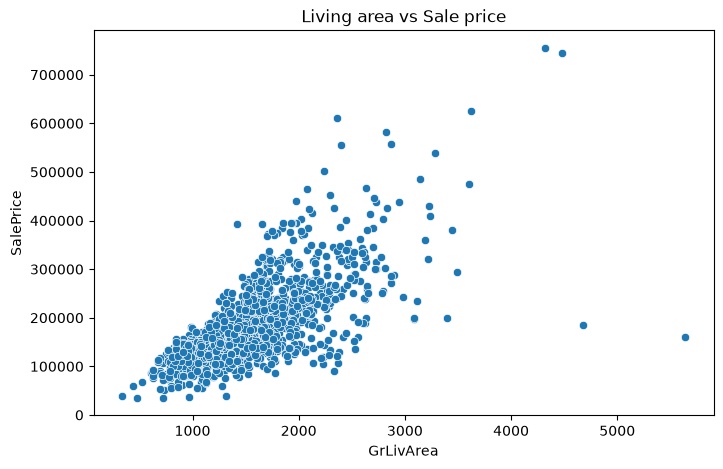

        Id  GrLivArea  SalePrice Neighborhood SaleCondition
523    524       4676     184750      Edwards       Partial
691    692       4316     755000      NoRidge        Normal
1182  1183       4476     745000      NoRidge       Abnorml
1298  1299       5642     160000      Edwards       Partial


In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="GrLivArea", y="SalePrice", data=df)
plt.title("Living area vs Sale price")
plt.show()

print(df.loc[df["GrLivArea"] > 4000, ["Id", "GrLivArea", "SalePrice", "Neighborhood", "SaleCondition"]])

In [9]:
df_clean = df[~((df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000))].copy()
print(df.shape, "->", df_clean.shape)
print("Removed Ids:", sorted(set(df["Id"]) - set(df_clean["Id"])))

(1460, 81) -> (1458, 81)
Removed Ids: [524, 1299]
